### 1. Imports & chargement des données

In [ ]:
import os
import shap
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, 
    f1_score, recall_score, make_scorer,
    precision_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

X_train = pd.read_csv("../data/weatherAUS_X_train.csv")
X_test  = pd.read_csv("../data/weatherAUS_X_test.csv")

y_train = pd.read_csv("../data/weatherAUS_y_train.csv").squeeze("columns")
y_test  = pd.read_csv("../data/weatherAUS_y_test.csv").squeeze("columns")

os.makedirs("../models/linear_svc", exist_ok=True)

### 2. Scaling

In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 3. Entraînement du modèle de base (LinearSVC)

In [21]:
model = LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
model.fit(X_train_scaled, y_train)

y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

y_score_train = model.decision_function(X_train_scaled)
y_score_test  = model.decision_function(X_test_scaled)

joblib.dump(model, "../models/linear_svc/linear_svc_baseline.pkl")

['../models/linear_svc/linear_svc_baseline.pkl']

#### 3.1 Métriques (F1, Recall, Précision, AUC-ROC, PR-AUC)

In [22]:
# Métriques du LinearSVC
f1_train = f1_score(y_train, y_pred_train, pos_label=1)
f1_test  = f1_score(y_test,  y_pred_test, pos_label=1)

recall_train   = recall_score(y_train, y_pred_train)
recall_test    = recall_score(y_test,  y_pred_test)

prec_train     = precision_score(y_train, y_pred_train)
prec_test      = precision_score(y_test,  y_pred_test)

auc_roc_train  = roc_auc_score(y_train, y_score_train)
auc_roc_test   = roc_auc_score(y_test,  y_score_test)

pr_auc_train   = average_precision_score(y_train, y_score_train)
pr_auc_test    = average_precision_score(y_test,  y_score_test)

In [23]:
sep = "─" * 52
print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LinearSVC':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train:>10.4f} {f1_test:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train:>10.4f} {recall_test:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train:>10.4f} {prec_test:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)

────────────────────────────────────────────────────
          ÉVALUATION DU MODÈLE — LinearSVC          
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.6275     0.6207
────────────────────────────────────────────────────
Recall  (classe Yes)             0.7768     0.7751
Précision (classe Yes)           0.5263     0.5176
────────────────────────────────────────────────────
AUC-ROC                          0.8759     0.8631
PR-AUC                           0.6984     0.6869
────────────────────────────────────────────────────


#### 3.2 Matrice de confusion

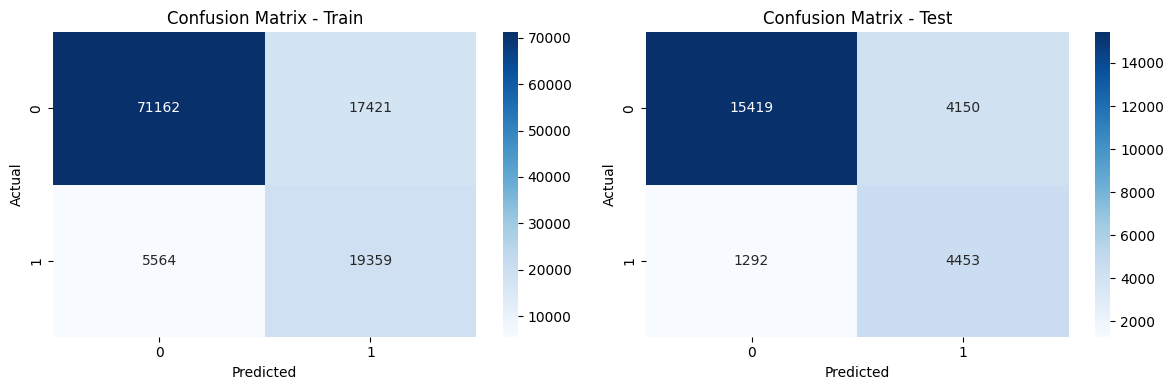

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, title in zip(axes, [y_pred_train, y_pred_test], ['Train', 'Test']):
    cm = confusion_matrix(y_train if title == 'Train' else y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

#### 3.3 Courbes AUC-ROC et PR-AUC

AUC-ROC - Train : 0.8759 | Test : 0.8631


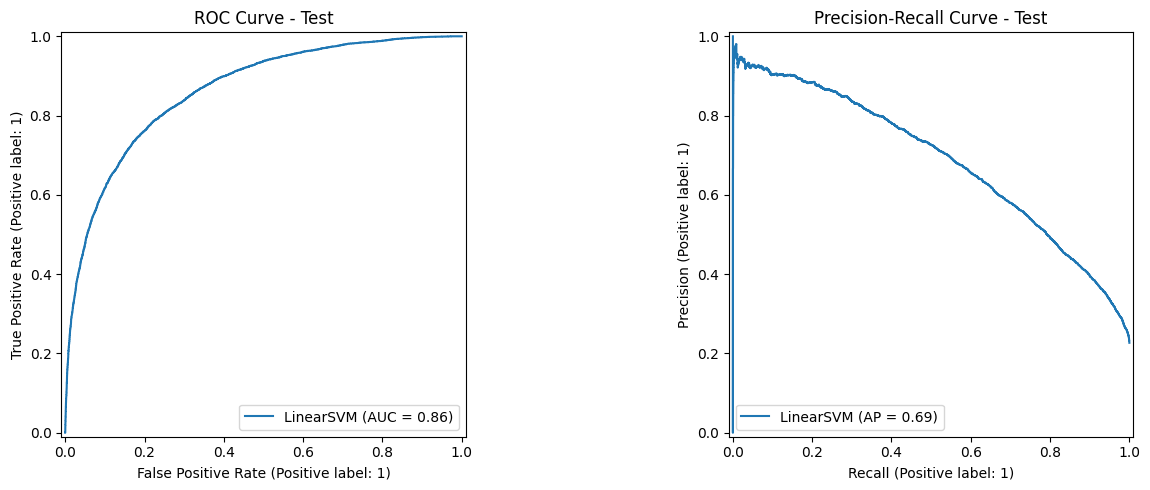

In [25]:
print(f"AUC-ROC - Train : {roc_auc_score(y_train, y_score_train):.4f} | Test : {roc_auc_score(y_test, y_score_test):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_test, y_score_test, ax=axes[0], name='LinearSVM')
axes[0].set_title('ROC Curve - Test')
PrecisionRecallDisplay.from_predictions(y_test, y_score_test, ax=axes[1], name='LinearSVM')
axes[1].set_title('Precision-Recall Curve - Test')
plt.tight_layout()
plt.show()

#### 3.4 Courbe Précision / Recall vs Seuil

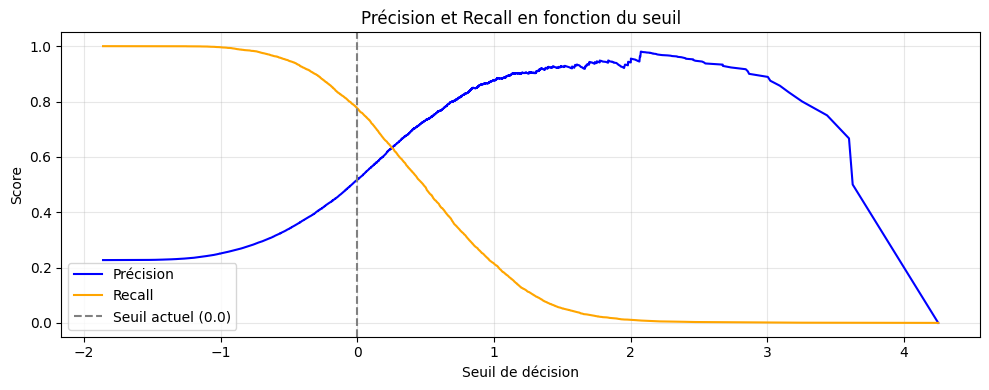

In [26]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_score_test)

plt.figure(figsize=(10, 4))
plt.plot(thresholds, precisions[:-1], label='Précision', color='blue')
plt.plot(thresholds, recalls[:-1],    label='Recall',    color='orange')
plt.axvline(x=0, color='gray', linestyle='--', label='Seuil actuel (0.0)')
plt.xlabel('Seuil de décision')
plt.ylabel('Score')
plt.title('Précision et Recall en fonction du seuil')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.5 Importance des features

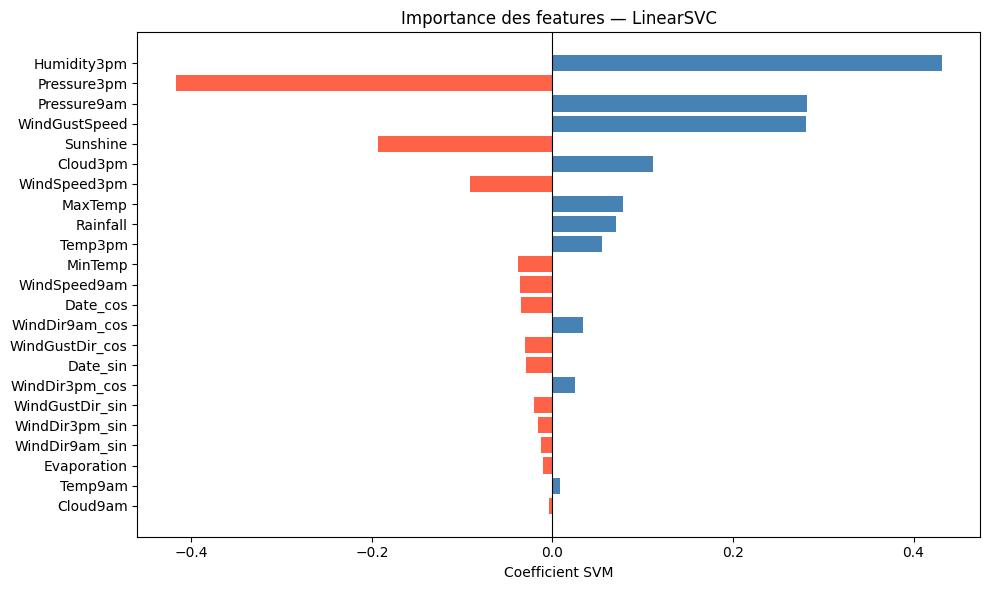

In [27]:
feature_names = X_train.columns
coefficients  = model.coef_[0]

coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefficients})
coef_df = coef_df.reindex(coef_df['coef'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(10, 6))
colors = ['tomato' if c < 0 else 'steelblue' for c in coef_df['coef']]
plt.barh(coef_df['feature'], coef_df['coef'], color=colors)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.xlabel('Coefficient SVM')
plt.title('Importance des features — LinearSVC')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Un coefficient positif (bleu) signifie "quand cette feature augmente, la probabilité de pluie augmente". 

Un coefficient négatif (rouge) signifie "quand cette feature augmente, la probabilité de pluie diminue".

#### 3.6 Courbe d'apprentissage (Learning Curve)

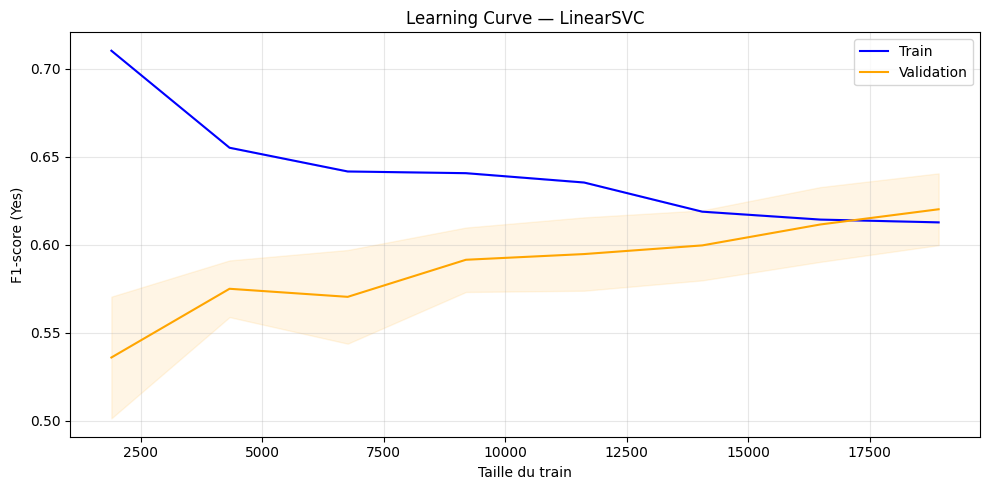

In [28]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train_scaled, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring='f1', cv=TimeSeriesSplit(n_splits=5), n_jobs=-1
)

plt.figure(figsize=(10, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), label='Train',      color='blue')
plt.plot(train_sizes, val_scores.mean(axis=1),   label='Validation', color='orange')
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='blue')
plt.fill_between(train_sizes,
                 val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='orange')
plt.xlabel('Taille du train')
plt.ylabel('F1-score (Yes)')
plt.title('Learning Curve — LinearSVC')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Optimisation des hyperparamètres

#### 4.1 Pipeline + Grid Search

In [29]:
# Pipeline : Scaler + LinearSVC 
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  LinearSVC(random_state=42, max_iter=5000))
])

# Grille d'hyperparamètres
# C : régularisation (petit = plus régularisé, grand = moins régularisé)
# loss : hinge (SVM classique) ou squared_hinge (plus stable, par défaut)
param_grid = {
    'model__C':            [0.01, 0.1, 1, 10],
    'model__loss':         ['hinge', 'squared_hinge'],
    'model__class_weight': ['balanced'],
}

# Cross-validation temporelle (respecte l'ordre chronologique, pas de stratification)
cv = TimeSeriesSplit(n_splits=5)

# Scorer : F1 pour la classe positive (insensible au déséquilibre)
scorer = make_scorer(f1_score, pos_label=1)

# Grid Search
grid_search = GridSearchCV(
    estimator  = pipe, 
    param_grid = param_grid, 
    scoring    = scorer, 
    cv         = cv, 
    n_jobs     = -1, 
    refit      = True 
)
grid_search.fit(X_train, y_train)

/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarnin

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': ['balanced'], 'model__loss': ['hinge', 'squared_hinge']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f..., pos_label=1)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the 

#### 4.2 Résultats & meilleurs paramètres

In [30]:
# Résultats des meilleurs hyperparamètres
sep = "─" * 52
print(f"\n{'GRID SEARCH — Meilleurs hyperparamètres':^52}")
print(sep)
for param, value in grid_search.best_params_.items():
    print(f"  {param:<35} {str(value):>12}")
print(sep)

# Évaluation du meilleur modèle
best_model = grid_search.best_estimator_
y_pred_test_gs  = best_model.predict(X_test)
y_pred_train_gs = best_model.predict(X_train)

# Scores du meilleur modèle
y_score_train_gs = best_model.decision_function(X_train)
y_score_test_gs  = best_model.decision_function(X_test)

# Métriques du meilleur modèle
f1_train_gs = f1_score(y_train, y_pred_train_gs, pos_label=1)
f1_test_gs  = f1_score(y_test,  y_pred_test_gs, pos_label=1)

recall_train_gs  = recall_score(y_train, y_pred_train_gs)
recall_test_gs   = recall_score(y_test,  y_pred_test_gs)

prec_train_gs    = precision_score(y_train, y_pred_train_gs)
prec_test_gs     = precision_score(y_test,  y_pred_test_gs)

auc_roc_train_gs = roc_auc_score(y_train, y_score_train_gs)
auc_roc_test_gs  = roc_auc_score(y_test,  y_score_test_gs)

pr_auc_train_gs  = average_precision_score(y_train, y_score_train_gs)
pr_auc_test_gs   = average_precision_score(y_test,  y_score_test_gs)

joblib.dump(best_model, "../models/linear_svc/linear_svc_grid_search.pkl")


      GRID SEARCH — Meilleurs hyperparamètres       
────────────────────────────────────────────────────
  model__C                                       1
  model__class_weight                     balanced
  model__loss                                hinge
────────────────────────────────────────────────────


['../models/linear_svc/linear_svc_grid_search.pkl']

#### 4.3 Comparaison Base vs Grid Search

In [31]:
print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LinearSVC':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train:>10.4f} {f1_test:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train:>10.4f} {recall_test:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train:>10.4f} {prec_test:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)
print("\n")

print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LinearSVC Grid Search':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train_gs:>10.4f} {f1_test_gs:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train_gs:>10.4f} {recall_test_gs:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train_gs:>10.4f} {prec_test_gs:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train_gs:>10.4f} {auc_roc_test_gs:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train_gs:>10.4f} {pr_auc_test_gs:>10.4f}")
print(sep)

────────────────────────────────────────────────────
          ÉVALUATION DU MODÈLE — LinearSVC          
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.6275     0.6207
────────────────────────────────────────────────────
Recall  (classe Yes)             0.7768     0.7751
Précision (classe Yes)           0.5263     0.5176
────────────────────────────────────────────────────
AUC-ROC                          0.8759     0.8631
PR-AUC                           0.6984     0.6869
────────────────────────────────────────────────────


────────────────────────────────────────────────────
    ÉVALUATION DU MODÈLE — LinearSVC Grid Search    
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.6288     0.6195
───────

### 5. Optimisation du seuil de décision

In [32]:
# Scan des seuils pour choisir le meilleur
print(sep)
print(f"{'SCAN DES SEUILS — Meilleur modèle Grid Search':^52}")
print(sep)
print(f"{'Seuil':<10} {'F1-score (Yes)':>10} {'Recall (Yes)':>10} {'Précision (Yes)':>10}")
print(sep)
for s in [-0.1, -0.2, -0.3, -0.4, -0.5]:
    y_pred_s = (y_score_test_gs >= s).astype(int)
    print(f"{s:<10} {f1_score(y_test, y_pred_s, pos_label=1):>10.4f} "
          f"{recall_score(y_test, y_pred_s, pos_label=1):>13.4f} "
          f"{precision_score(y_test, y_pred_s, pos_label=1):>13.4f}")
print(sep)
print("\n")

# Application du seuil personnalisé choisi
seuil = -0.1
y_pred_custom_gs = (y_score_test_gs >= seuil).astype(int)

print(sep)
print(f"{'IMPACT DU SEUIL PERSONNALISÉ (Grid Search)':^52}")
print(sep)
print(f"{'Métrique':<28} {'Défaut (0.0)':>10} {f'Seuil {seuil}':>10}")
print(sep)
print(f"{'F1-score (Yes)':<28} {f1_test_gs:>10.4f} "
      f"{f1_score(y_test, y_pred_custom_gs, pos_label=1):>10.4f}")
print(f"{'Recall (Yes)':<28} {recall_score(y_test, y_pred_test_gs):>10.4f} "
      f"{recall_score(y_test, y_pred_custom_gs):>10.4f}")
print(f"{'Précision (Yes)':<28} {precision_score(y_test, y_pred_test_gs):>10.4f} "
      f"{precision_score(y_test, y_pred_custom_gs):>10.4f}")
print(sep)
print(f"{'AUC-ROC (inchangé)':<28} {auc_roc_test_gs:>10.4f} {auc_roc_test_gs:>10.4f}")
print(f"{'PR-AUC  (inchangé)':<28} {pr_auc_test_gs:>10.4f} {pr_auc_test_gs:>10.4f}")
print(sep)

────────────────────────────────────────────────────
   SCAN DES SEUILS — Meilleur modèle Grid Search    
────────────────────────────────────────────────────
Seuil      F1-score (Yes) Recall (Yes) Précision (Yes)
────────────────────────────────────────────────────
-0.1           0.6130        0.7983        0.4975
-0.2           0.6027        0.8178        0.4772
-0.3           0.5907        0.8341        0.4573
-0.4           0.5807        0.8550        0.4397
-0.5           0.5706        0.8738        0.4236
────────────────────────────────────────────────────


────────────────────────────────────────────────────
     IMPACT DU SEUIL PERSONNALISÉ (Grid Search)     
────────────────────────────────────────────────────
Métrique                     Défaut (0.0) Seuil -0.1
────────────────────────────────────────────────────
F1-score (Yes)                   0.6195     0.6130
Recall (Yes)                     0.7739     0.7983
Précision (Yes)                  0.5164     0.4975
──────────

In [33]:
# ── Prédictions avec le seuil personnalisé ────────────────────────────────────
seuil = -0.1
y_pred_custom_train = (y_score_train_gs >= seuil).astype(int)
y_pred_custom_test  = (y_score_test_gs  >= seuil).astype(int)

# ── Métriques du modèle avec seuil personnalisé ───────────────────────────────
# AUC-ROC et PR-AUC : inchangées (indépendantes du seuil)
# On réutilise y_score_train_gs et y_score_test_gs déjà calculés

f1_train_custom = f1_score(y_train, y_pred_custom_train, pos_label=1)
f1_test_custom  = f1_score(y_test,  y_pred_custom_test, pos_label=1)

recall_train_custom   = recall_score(y_train, y_pred_custom_train)
recall_test_custom    = recall_score(y_test,  y_pred_custom_test)

prec_train_custom     = precision_score(y_train, y_pred_custom_train)
prec_test_custom      = precision_score(y_test,  y_pred_custom_test)

joblib.dump({"model": best_model, "seuil": seuil, "features": list(X_train.columns)}, "../models/linear_svc/linear_svc_threshold.pkl")

['../models/linear_svc/linear_svc_threshold.pkl']

In [34]:
print(sep)
print(f"{'ÉVALUATION — LinearSVC GS + Seuil -0.1':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train_custom:>10.4f} {f1_test_custom:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train_custom:>10.4f} {recall_test_custom:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train_custom:>10.4f} {prec_test_custom:>10.4f}")
print(sep)
print(f"{'AUC-ROC (inchangé)':<28} {auc_roc_train_gs:>10.4f} {auc_roc_test_gs:>10.4f}")
print(f"{'PR-AUC  (inchangé)':<28} {pr_auc_train_gs:>10.4f} {pr_auc_test_gs:>10.4f}")
print(sep)

────────────────────────────────────────────────────
       ÉVALUATION — LinearSVC GS + Seuil -0.1       
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.6210     0.6130
────────────────────────────────────────────────────
Recall  (classe Yes)             0.8018     0.7983
Précision (classe Yes)           0.5068     0.4975
────────────────────────────────────────────────────
AUC-ROC (inchangé)               0.8763     0.8637
PR-AUC  (inchangé)               0.6963     0.6843
────────────────────────────────────────────────────


### 6. Interprétabilité du modèle (SHAP)

Background dataset has 113506 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=113506 when initializing the masker.


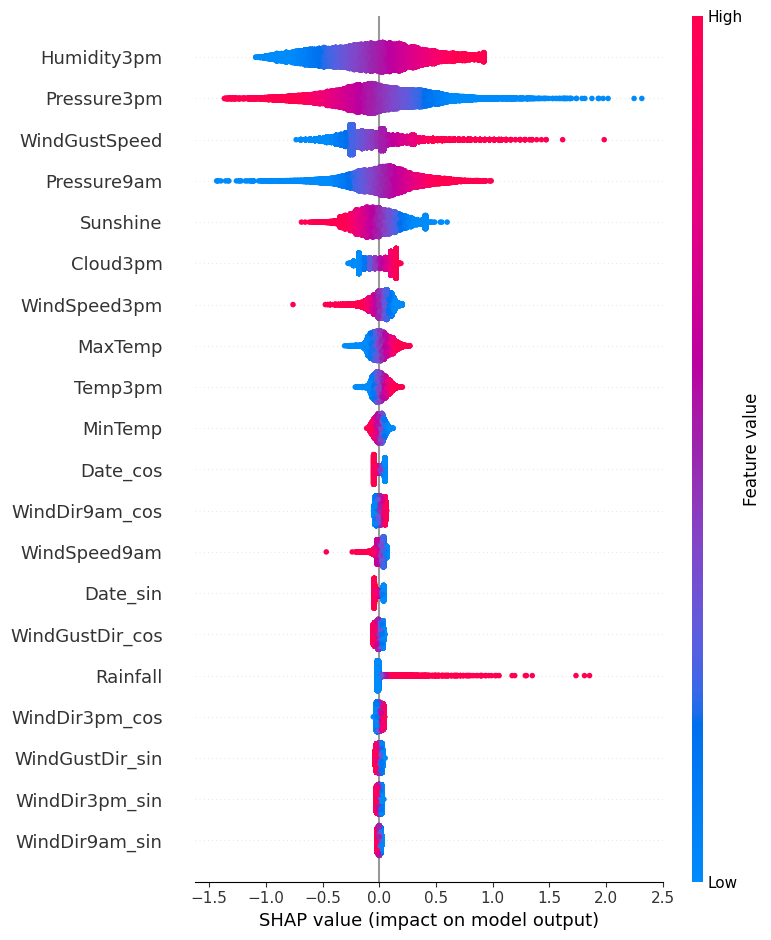

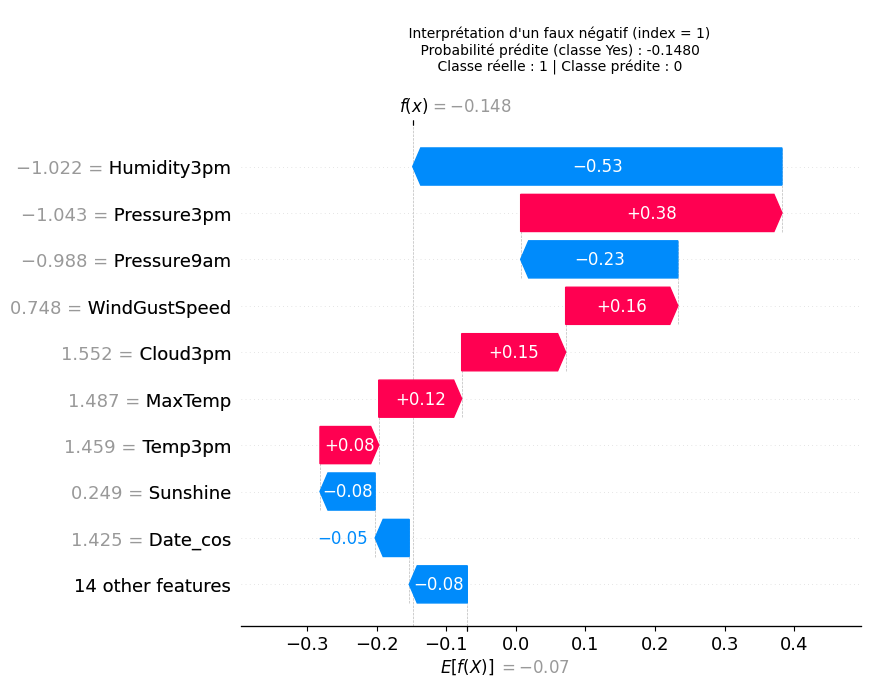

In [35]:
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

explainer = shap.LinearExplainer(model, X_train_scaled)
shap_values = explainer.shap_values(X_test_scaled)

# Summary plot : vue d'ensemble avec direction d'effet
shap.summary_plot(shap_values, X_test_scaled)

# Waterfall plot : interprétation d'une prédiction individuelle (faux négatif)
y_test_arr = y_test.values.ravel()
fn_mask = (y_test_arr == 1) & (y_pred_test == 0)
fn_indices = np.where(fn_mask)[0]
idx = fn_indices[0]
plt.title(f"""
    Interprétation d'un faux négatif (index = {idx})
    Probabilité prédite (classe Yes) : {y_score_test[idx]:.4f}
    Classe réelle : {y_test_arr[idx]} | Classe prédite : {y_pred_test[idx]}
""", fontsize=10)
explanation_test = explainer(X_test_scaled.iloc[[idx]])
shap.plots.waterfall(explanation_test[0])